# Notebook 04 (v2) - Third arm: CLIP fine-tuned on VisDrone, with a proper held-out split

**This version fixes two issues found after the first run:**

1. **Bicycle mapping** - `VISDRONE_TO_COMMON` no longer maps `bicycle` into `small-vehicle`.
   DOTA's `small-vehicle` label is satellite-altitude and can only resolve cars, not bicycles;
   mixing the two visually distinct object types into one bucket (bicycles were ~5.8% of it)
   added noise to the small-vehicle drift number. Fixed in `src/dataset.py`.

2. **Train/eval leakage (the important one)** - the first version fine-tuned on *every* VisDrone
   image, then drew its evaluation sample from that same complete pool. That means the "how well
   does this model represent VisDrone" measurement was computed on images it had already been
   directly trained to represent well - the reported 63% drift reduction was likely inflated by
   memorization, not a clean measure of generalization.

   **Fix:** VisDrone images are split by filename into an 80% training pool and a 20% held-out
   pool *before* any crops are extracted (fixed seed, so it's reproducible). Fine-tuning only
   ever sees the training pool. Evaluation only ever draws from the held-out pool - genuinely
   unseen data. DOTA needs no such split (it was never part of training in the first place).

   **For a fair three-way comparison, CLIP and RemoteCLIP are also re-evaluated on this same
   held-out VisDrone sample** (not the old evaluation crops from the first run), so all three
   arms are compared on identical, leakage-free data.

**Outputs are saved under new filenames** (`*_heldout.*`) rather than overwriting the first
run's results - so the original (leaky) numbers stay around for reference/comparison rather than
silently disappearing.

**How to run this:** same as before - run interactively in Jupyter/VS Code (cell-by-cell or
"Run All" against a live kernel), not via `jupyter nbconvert --execute`, so you get live progress.
Training scope is slightly smaller than the first run (80% of VisDrone instead of 100%), so
expect roughly 80% of the previous training time.


In [1]:
import os
import sys
import json
import time
import random

import numpy as np
import torch
import matplotlib.pyplot as plt
from numpy.linalg import norm

sys.path.insert(0, os.path.abspath(".."))
from src.dataset import COMMON_VOCAB, VISDRONE_TO_COMMON, get_dota_crops, get_visdrone_crops, subsample_balanced
from src.embeddings import load_clip, load_remoteclip, encode_with_clip, encode_with_remoteclip, finetune_clip_on_crops

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

DOTA_IMG_DIR = "../data/raw/DOTA/images"
DOTA_LABEL_DIR = "../data/raw/DOTA/labelTxt"
VISDRONE_BASE = "../data/raw/VisDrone/VisDrone2019-DET-train"
VISDRONE_IMG_DIR = os.path.join(VISDRONE_BASE, "images")
VISDRONE_ANN_DIR = os.path.join(VISDRONE_BASE, "annotations")

# Evaluation scope
EVAL_MAX_CROPS_PER_CLASS = 300
EVAL_SEED = 42

# Train/held-out split (image-level, so no image contributes crops to both sets)
HOLDOUT_FRACTION = 0.2
SPLIT_SEED = 1234

# Training scope
MAX_TRAIN_CROPS_PER_CLASS = None  # None = use every mapped crop from the training-pool images
NUM_EPOCHS = 3
TRAIN_BATCH_SIZE = 8
LEARNING_RATE = 1e-5
PROMPT_TEMPLATE = "a drone photo of a {}"

CHECKPOINT_DIR = "../models/finetuned_clip_visdrone_heldout"
EMBED_OUT = "../embeddings/remoteclip_vs_clip"
RESULTS_OUT = "../results/remoteclip_vs_clip"
os.makedirs(EMBED_OUT, exist_ok=True)
os.makedirs(RESULTS_OUT, exist_ok=True)


device: cuda


## Split VisDrone into a training pool and a held-out pool, by image

In [2]:
all_ann_files = sorted(os.listdir(VISDRONE_ANN_DIR))
rng = random.Random(SPLIT_SEED)
shuffled = all_ann_files[:]
rng.shuffle(shuffled)

n_holdout = int(len(shuffled) * HOLDOUT_FRACTION)
holdout_files = set(shuffled[:n_holdout])
train_files = set(shuffled[n_holdout:])

print(f"VisDrone images: {len(all_ann_files)} total -> {len(train_files)} train-pool, {len(holdout_files)} held-out-pool")
assert train_files.isdisjoint(holdout_files), "train/held-out split must not overlap"


VisDrone images: 6471 total -> 5177 train-pool, 1294 held-out-pool


## Training data - training-pool images only, all 4 mapped classes

In [3]:
from collections import Counter

VISDRONE_TRAIN_MAP = dict(VISDRONE_TO_COMMON)
VISDRONE_TRAIN_MAP.update({
    "motor": "motorcycle", "tricycle": "motorcycle", "awning-tricycle": "motorcycle",
    "pedestrian": "person", "person": "person",
})

t0 = time.time()
visdrone_train_crops_all = get_visdrone_crops(
    VISDRONE_IMG_DIR, VISDRONE_ANN_DIR, class_map=VISDRONE_TRAIN_MAP, allowed_files=train_files,
)
print(f"VisDrone training crops (train-pool only, all mapped classes): {len(visdrone_train_crops_all)}  ({time.time()-t0:.1f}s)")
print("Class distribution:", dict(Counter(c for _, c in visdrone_train_crops_all)))

if MAX_TRAIN_CROPS_PER_CLASS is not None:
    visdrone_train_crops = subsample_balanced(visdrone_train_crops_all, MAX_TRAIN_CROPS_PER_CLASS, EVAL_SEED)
    print(f"Subsampled training set to {len(visdrone_train_crops)} crops (max {MAX_TRAIN_CROPS_PER_CLASS}/class)")
else:
    visdrone_train_crops = visdrone_train_crops_all
    print(f"Using full training-pool set: {len(visdrone_train_crops)} crops")


VisDrone training crops (train-pool only, all mapped classes): 167699  (103.8s)
Class distribution: {'small-vehicle': 87199, 'large-vehicle': 29723, 'motorcycle': 19003, 'person': 31774}
Using full training-pool set: 167699 crops


## Fine-tune CLIP ViT-B/32 on VisDrone (training-pool images only)

Progress logs every 20 steps: loss, running average, throughput, and an ETA for the current
epoch. Checkpoints save after every epoch to `models/finetuned_clip_visdrone_heldout/` (a new
directory, so the first run's checkpoints in `finetuned_clip_visdrone/` are left untouched).

In [4]:
base_model, processor = load_clip(device)

finetuned_model = finetune_clip_on_crops(
    visdrone_train_crops, base_model, processor, device,
    num_epochs=NUM_EPOCHS, batch_size=TRAIN_BATCH_SIZE, lr=LEARNING_RATE,
    prompt_template=PROMPT_TEMPLATE,
    checkpoint_dir=CHECKPOINT_DIR, checkpoint_prefix="finetuned_clip_visdrone_heldout",
    progress_every=20, log=print,
)
print("Fine-tuning complete.")


c:\anaconda\envs\hf\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


trainable params: 14,570,496 / 151,277,313
  epoch 1/3 step 20/20963 loss=1.5860 avg_loss=2.2003 47.9 crops/s elapsed=3s eta_this_epoch=3494s
  epoch 1/3 step 40/20963 loss=1.9656 avg_loss=2.0584 60.8 crops/s elapsed=5s eta_this_epoch=2753s
  epoch 1/3 step 60/20963 loss=1.5273 avg_loss=1.9616 66.6 crops/s elapsed=7s eta_this_epoch=2510s
  epoch 1/3 step 80/20963 loss=1.5921 avg_loss=1.9128 70.3 crops/s elapsed=9s eta_this_epoch=2376s
  epoch 1/3 step 100/20963 loss=1.3164 avg_loss=1.8755 72.8 crops/s elapsed=11s eta_this_epoch=2292s
  epoch 1/3 step 120/20963 loss=1.6063 avg_loss=1.8393 74.4 crops/s elapsed=13s eta_this_epoch=2241s
  epoch 1/3 step 140/20963 loss=1.7221 avg_loss=1.8286 75.7 crops/s elapsed=15s eta_this_epoch=2200s
  epoch 1/3 step 160/20963 loss=1.4070 avg_loss=1.8044 76.9 crops/s elapsed=17s eta_this_epoch=2164s
  epoch 1/3 step 180/20963 loss=1.3735 avg_loss=1.7907 77.7 crops/s elapsed=19s eta_this_epoch=2139s
  epoch 1/3 step 200/20963 loss=1.5621 avg_loss=1.7728 7

## Evaluation crops - DOTA (full scan, unchanged) + VisDrone (held-out pool only, genuinely unseen)

In [5]:
t0 = time.time()
dota_crops_all = get_dota_crops(DOTA_IMG_DIR, DOTA_LABEL_DIR)
dota_eval_crops = subsample_balanced(dota_crops_all, EVAL_MAX_CROPS_PER_CLASS, EVAL_SEED)
print(f"DOTA eval crops: {len(dota_eval_crops)}  ({time.time()-t0:.1f}s)  {dict(Counter(c for _, c in dota_eval_crops))}")

t0 = time.time()
visdrone_crops_all_eval = get_visdrone_crops(
    VISDRONE_IMG_DIR, VISDRONE_ANN_DIR, allowed_files=holdout_files,  # default class_map = fixed VISDRONE_TO_COMMON (no bicycle)
)
visdrone_eval_crops = subsample_balanced(visdrone_crops_all_eval, EVAL_MAX_CROPS_PER_CLASS, EVAL_SEED)
print(f"VisDrone eval crops (held-out pool only): {len(visdrone_eval_crops)}  ({time.time()-t0:.1f}s)  {dict(Counter(c for _, c in visdrone_eval_crops))}")


DOTA eval crops: 600  (26.8s)  {'small-vehicle': 300, 'large-vehicle': 300}
VisDrone eval crops (held-out pool only): 600  (28.0s)  {'small-vehicle': 300, 'large-vehicle': 300}


## Encode all three arms on this identical, leakage-free crop set

CLIP and RemoteCLIP are re-run here (not loaded from the first run's saved results) so all three
arms are compared on exactly the same held-out data.

In [6]:
t0 = time.time()
dota_ft_feats, dota_ft_labels = encode_with_clip(dota_eval_crops, finetuned_model, processor, device, batch_size=16, log=print)
visdrone_ft_feats, visdrone_ft_labels = encode_with_clip(visdrone_eval_crops, finetuned_model, processor, device, batch_size=16, log=print)
print(f"Fine-tuned CLIP: DOTA {dota_ft_feats.shape}, VisDrone {visdrone_ft_feats.shape}  ({time.time()-t0:.1f}s)")


  [clip] 160/600 crops, 119.9 crops/s, 1s elapsed
  [clip] 320/600 crops, 131.6 crops/s, 2s elapsed
  [clip] 480/600 crops, 134.3 crops/s, 4s elapsed
  [clip] 160/600 crops, 134.7 crops/s, 1s elapsed
  [clip] 320/600 crops, 139.7 crops/s, 2s elapsed
  [clip] 480/600 crops, 143.5 crops/s, 3s elapsed
Fine-tuned CLIP: DOTA (600, 512), VisDrone (600, 512)  (8.5s)


In [7]:
clip_model, clip_processor = load_clip(device)

t0 = time.time()
dota_clip_feats, dota_clip_labels = encode_with_clip(dota_eval_crops, clip_model, clip_processor, device, batch_size=16, log=print)
visdrone_clip_feats, visdrone_clip_labels = encode_with_clip(visdrone_eval_crops, clip_model, clip_processor, device, batch_size=16, log=print)
print(f"CLIP: DOTA {dota_clip_feats.shape}, VisDrone {visdrone_clip_feats.shape}  ({time.time()-t0:.1f}s)")


  [clip] 160/600 crops, 129.2 crops/s, 1s elapsed
  [clip] 320/600 crops, 146.8 crops/s, 2s elapsed
  [clip] 480/600 crops, 150.0 crops/s, 3s elapsed
  [clip] 160/600 crops, 168.9 crops/s, 1s elapsed
  [clip] 320/600 crops, 167.3 crops/s, 2s elapsed
  [clip] 480/600 crops, 167.0 crops/s, 3s elapsed
CLIP: DOTA (600, 512), VisDrone (600, 512)  (7.5s)


In [8]:
remoteclip_model, remoteclip_preprocess = load_remoteclip("../models/RemoteCLIP/RemoteCLIP-ViT-L-14.pt", device)

t0 = time.time()
dota_rc_feats, dota_rc_labels = encode_with_remoteclip(dota_eval_crops, remoteclip_model, remoteclip_preprocess, device, batch_size=16, log=print)
visdrone_rc_feats, visdrone_rc_labels = encode_with_remoteclip(visdrone_eval_crops, remoteclip_model, remoteclip_preprocess, device, batch_size=16, log=print)
print(f"RemoteCLIP: DOTA {dota_rc_feats.shape}, VisDrone {visdrone_rc_feats.shape}  ({time.time()-t0:.1f}s)")


c:\Users\Kabir Oberoi\Desktop\Capstone\src\embeddings.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=device)


  [remoteclip] 160/600 crops, 2.4 crops/s, 67s elapsed
  [remoteclip] 320/600 crops, 2.4 crops/s, 135s elapsed
  [remoteclip] 480/600 crops, 2.4 crops/s, 203s elapsed
  [remoteclip] 160/600 crops, 1.8 crops/s, 90s elapsed
  [remoteclip] 320/600 crops, 1.7 crops/s, 188s elapsed
  [remoteclip] 480/600 crops, 1.7 crops/s, 284s elapsed
RemoteCLIP: DOTA (600, 768), VisDrone (600, 768)  (611.9s)


## Three-way drift comparison (held-out, leakage-free)

In [9]:
def compute_drift(dota_feats, dota_labels, vis_feats, vis_labels):
    scores = {}
    for cls in COMMON_VOCAB:
        sat = dota_feats[dota_labels == cls]
        uav = vis_feats[vis_labels == cls]
        if len(sat) == 0 or len(uav) == 0:
            continue
        sat_c, uav_c = sat.mean(axis=0), uav.mean(axis=0)
        l2 = float(norm(sat_c - uav_c))
        cos = float(1 - np.dot(sat_c, uav_c) / (norm(sat_c) * norm(uav_c)))
        sat_intra = float(np.mean(norm(sat - sat_c, axis=1)))
        uav_intra = float(np.mean(norm(uav - uav_c, axis=1)))
        scores[cls] = {
            "l2_drift": round(l2, 4),
            "cosine_drift": round(cos, 4),
            "drift_ratio": round(l2 / ((sat_intra + uav_intra) / 2), 4),
            "sat_samples": int(len(sat)),
            "uav_samples": int(len(uav)),
        }
    return scores


clip_drift = compute_drift(dota_clip_feats, dota_clip_labels, visdrone_clip_feats, visdrone_clip_labels)
remoteclip_drift = compute_drift(dota_rc_feats, dota_rc_labels, visdrone_rc_feats, visdrone_rc_labels)
finetuned_drift = compute_drift(dota_ft_feats, dota_ft_labels, visdrone_ft_feats, visdrone_ft_labels)

print(f"{'class':<16}{'CLIP':>10}{'RemoteCLIP':>12}{'FT-CLIP(VisDrone)':>20}{'lowest':>14}")
for cls in COMMON_VOCAB:
    vals = {"CLIP": clip_drift[cls]["l2_drift"], "RemoteCLIP": remoteclip_drift[cls]["l2_drift"], "FT-CLIP(VisDrone)": finetuned_drift[cls]["l2_drift"]}
    lowest = min(vals, key=vals.get)
    print(f"{cls:<16}{vals['CLIP']:>10.4f}{vals['RemoteCLIP']:>12.4f}{vals['FT-CLIP(VisDrone)']:>20.4f}{lowest:>14}")


class                 CLIP  RemoteCLIP   FT-CLIP(VisDrone)        lowest
small-vehicle       0.2460      0.1892              0.1585FT-CLIP(VisDrone)
large-vehicle       0.2596      0.2276              0.0955FT-CLIP(VisDrone)


**How to read this compared to the first run:** if the fine-tuned arm's drift numbers here are
noticeably higher (closer to CLIP/RemoteCLIP) than the first run's 0.141/0.096, that confirms the
first run's low numbers were substantially driven by memorization. If they're still clearly lower
than CLIP/RemoteCLIP, that's a much more trustworthy version of the original finding - now backed
by genuinely unseen evaluation data.

## Visualization

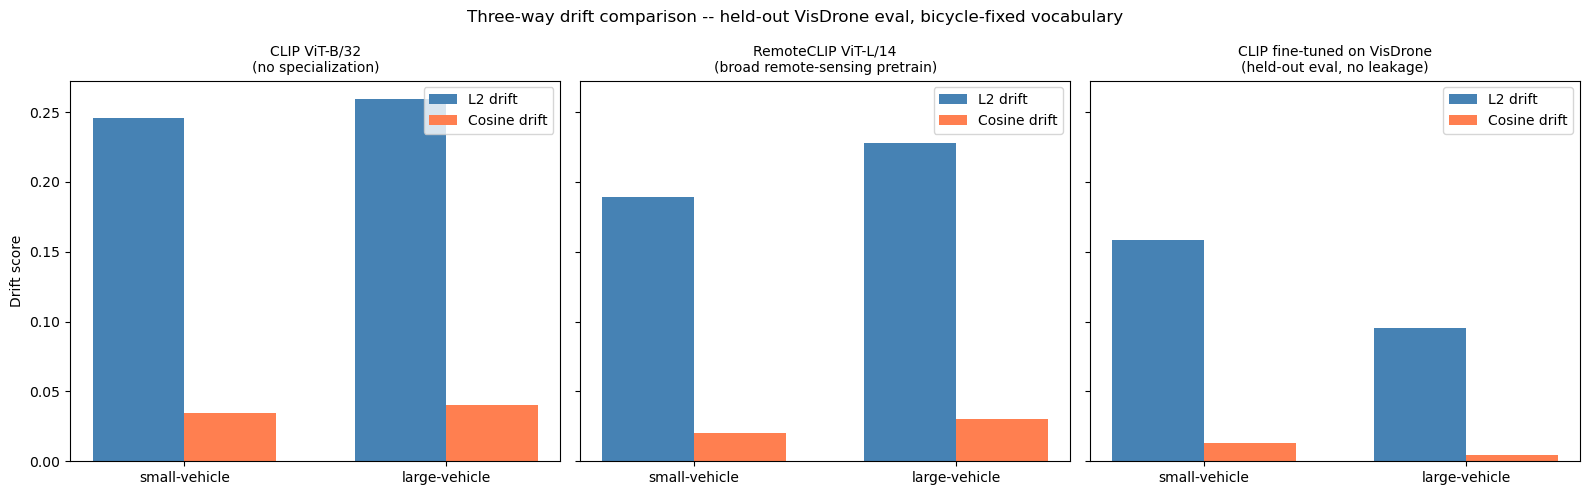

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
arms = [("CLIP ViT-B/32\n(no specialization)", clip_drift),
        ("RemoteCLIP ViT-L/14\n(broad remote-sensing pretrain)", remoteclip_drift),
        ("CLIP fine-tuned on VisDrone\n(held-out eval, no leakage)", finetuned_drift)]

for ax, (name, drift) in zip(axes, arms):
    classes = list(drift.keys())
    l2 = [drift[c]["l2_drift"] for c in classes]
    cos = [drift[c]["cosine_drift"] for c in classes]
    x = np.arange(len(classes))
    width = 0.35
    ax.bar(x - width/2, l2, width, label="L2 drift", color="steelblue")
    ax.bar(x + width/2, cos, width, label="Cosine drift", color="coral")
    ax.set_xticks(x)
    ax.set_xticklabels(classes)
    ax.set_title(name, fontsize=10)
    ax.legend()
axes[0].set_ylabel("Drift score")
plt.suptitle("Three-way drift comparison -- held-out VisDrone eval, bicycle-fixed vocabulary")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_OUT, "three_way_drift_comparison_heldout.png"), dpi=150, bbox_inches="tight")
plt.show()


## Save

In [11]:
np.save(os.path.join(EMBED_OUT, "dota_finetuned_clip_heldout_feats.npy"), dota_ft_feats)
np.save(os.path.join(EMBED_OUT, "dota_finetuned_clip_heldout_labels.npy"), dota_ft_labels)
np.save(os.path.join(EMBED_OUT, "visdrone_finetuned_clip_heldout_feats.npy"), visdrone_ft_feats)
np.save(os.path.join(EMBED_OUT, "visdrone_finetuned_clip_heldout_labels.npy"), visdrone_ft_labels)

with open(os.path.join(RESULTS_OUT, "drift_comparison_3way_heldout.json"), "w") as f:
    json.dump({
        "clip_vit_b32": clip_drift,
        "remoteclip_vit_l14": remoteclip_drift,
        "finetuned_clip_visdrone_heldout": finetuned_drift,
        "eval_max_crops_per_class": EVAL_MAX_CROPS_PER_CLASS,
        "eval_seed": EVAL_SEED,
        "holdout_fraction": HOLDOUT_FRACTION,
        "split_seed": SPLIT_SEED,
        "train_num_epochs": NUM_EPOCHS,
        "train_batch_size": TRAIN_BATCH_SIZE,
        "train_lr": LEARNING_RATE,
        "prompt_template": PROMPT_TEMPLATE,
        "notes": "Fixes vs first run: (1) bicycle removed from small-vehicle mapping, (2) VisDrone "
                 "split 80/20 train/held-out by image before any crop extraction, fine-tuning only "
                 "sees the 80% pool, all three arms evaluated only on the 20% held-out pool.",
    }, f, indent=2)

print("Saved embeddings to", EMBED_OUT)
print("Saved corrected 3-way results to", os.path.join(RESULTS_OUT, "drift_comparison_3way_heldout.json"))
print("Saved plot to", os.path.join(RESULTS_OUT, "three_way_drift_comparison_heldout.png"))
print("Fine-tuned checkpoints in", CHECKPOINT_DIR)


Saved embeddings to ../embeddings/remoteclip_vs_clip
Saved corrected 3-way results to ../results/remoteclip_vs_clip\drift_comparison_3way_heldout.json
Saved plot to ../results/remoteclip_vs_clip\three_way_drift_comparison_heldout.png
Fine-tuned checkpoints in ../models/finetuned_clip_visdrone_heldout
